In [7]:
import datetime
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

NUM_NODES = 2_181_021_971

In [4]:
prefix = "./results/output"

cols = {name: np.fromfile(f"{prefix}.{ext}", dtype="<u4")
        for name, ext in [("d_max", "dmax"), ("d_min", "dmin"),
                          ("src_max", "srcmax"), ("src_min", "srcmin")]}

n = len(cols["d_max"])
df = pl.DataFrame({"output_id": np.arange(n, dtype=np.uint32), **cols})
print(df.head())

shape: (5, 5)
┌───────────┬───────┬───────┬─────────┬─────────┐
│ output_id ┆ d_max ┆ d_min ┆ src_max ┆ src_min │
│ ---       ┆ ---   ┆ ---   ┆ ---     ┆ ---     │
│ u32       ┆ u32   ┆ u32   ┆ u32     ┆ u32     │
╞═══════════╪═══════╪═══════╪═════════╪═════════╡
│ 0         ┆ 0     ┆ 0     ┆ 0       ┆ 0       │
│ 1         ┆ 0     ┆ 0     ┆ 1       ┆ 1       │
│ 2         ┆ 0     ┆ 0     ┆ 2       ┆ 2       │
│ 3         ┆ 0     ┆ 0     ┆ 3       ┆ 3       │
│ 4         ┆ 0     ┆ 0     ┆ 4       ┆ 4       │
└───────────┴───────┴───────┴─────────┴─────────┘


In [ ]:
df.write_parquet("results/output.parquet", compression="zstd", compression_level=12)

In [8]:
df = pl.read_parquet("results/output.parquet")
df

output_id,d_max,d_min,src_max,src_min
u32,u32,u32,u32,u32
0,0,0,0,0
1,0,0,1,1
2,0,0,2,2
3,0,0,3,3
4,0,0,4,4
…,…,…,…,…
2181021966,3558962,10,84564,2170638570
2181021967,3558962,10,84564,2170638570
2181021968,3547511,6,84564,2156469884


In [8]:
dmax_dist = df.group_by("d_max").len(name="count")
dmax_dist

d_max,count
u32,u32
1549106,42
2921281,712
945914,739
2967298,1188
3304699,98
…,…
193035,58
1918861,305
2583451,478


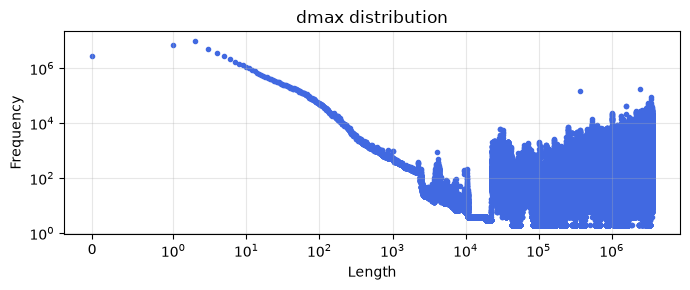

In [11]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.scatter(dmax_dist['d_max'], dmax_dist['count'], color="royalblue", marker='.')
ax.set_xscale("symlog", linthresh=1)
ax.set_yscale("log")
ax.set_xlabel("Length")
ax.set_ylabel("Frequency")
ax.set_title("dmax distribution")
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

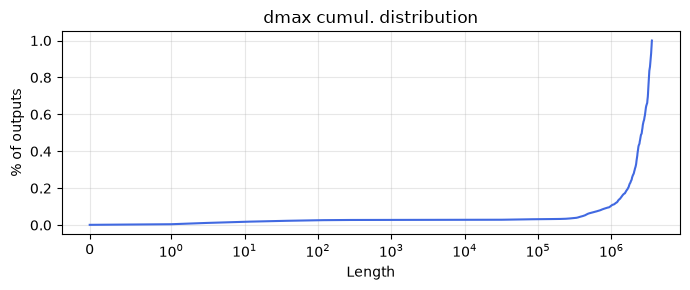

In [ ]:
x = dmax_dist.sort('d_max').with_columns(cumulative_perc = pl.col("count").cum_sum() / NUM_NODES)
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(x['d_max'], x['cumulative_perc'], color="royalblue")
ax.set_xscale("symlog", linthresh=1)
ax.set_xlabel("Length")
ax.set_ylabel("% of outputs")
ax.set_title("dmax cumul. distribution")
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
dmin_dist = df.group_by("d_min").len(name="count")
dmin_dist

d_min,count
u32,u32
12070,39
9581,166
11832,44
12213,31
13812,24
…,…
6151,635
14377,22
1658,17438


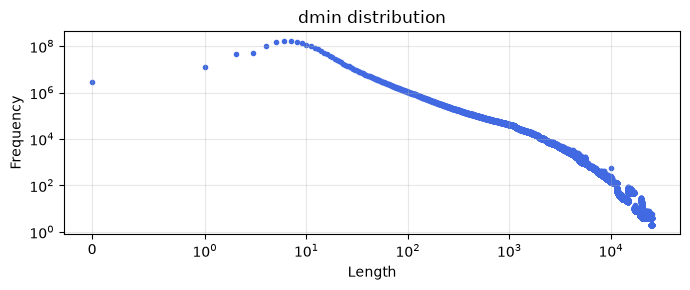

In [20]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.scatter(dmin_dist['d_min'], dmin_dist['count'], color="royalblue", marker='.')
ax.set_xscale("symlog", linthresh=1)
ax.set_yscale("log")
ax.set_xlabel("Length")
ax.set_ylabel("Frequency")
ax.set_title("dmin distribution")
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

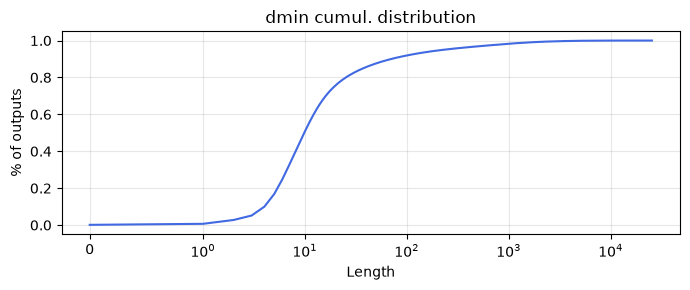

In [21]:
x = dmin_dist.sort('d_min').with_columns(cumulative_perc = pl.col("count").cum_sum() / NUM_NODES)
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(x['d_min'], x['cumulative_perc'], color="royalblue")
ax.set_xscale("symlog", linthresh=1)
ax.set_xlabel("Length")
ax.set_ylabel("% of outputs")
ax.set_title("dmin cumul. distribution")
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

In [24]:
df.group_by("src_max").len(name="count").sort("count", descending=True)

src_max,count
u32,u32
84564,2119286860
29980492,311324
1603011,248922
643178625,139626
786244931,136526
…,…
6909865,1
178900726,1
183899840,1


In [ ]:
def weighted_mean_std(df: pl.DataFrame, value_col: str, count_col: str) -> tuple[float, float]:
    """Calcola media e deviazione standard della popolazione pesate per frequenza."""
    result = df.select(
        (
            (pl.col(value_col) * pl.col(count_col)).sum()
            / pl.col(count_col).sum()
        ).alias("mean"),
        (
            (
                pl.col(count_col)
                * (
                    pl.col(value_col)
                    - (
                        (pl.col(value_col) * pl.col(count_col)).sum()
                        / pl.col(count_col).sum()
                    )
                ).pow(2)
            ).sum()
            / pl.col(count_col).sum()
        ).sqrt().alias("std"),
    )
    return result.row(0)

names = [f"dist_{year}_H{h}.bin" for year in range(2009, 2023) for h in [1, 2]]
dates = [datetime.date(year, 6, 30) if h == 1 else datetime.date(year, 12, 31) for year in range(2009, 2023) for h in [1, 2]]
d_max_means = []
d_max_devs = []
d_min_means = []
d_min_devs = []

for i in range(0, len(names)):
    with open(f"results/dist_dmax/{names[i]}", "rb") as f:
        arr = np.fromfile(f, dtype=np.dtype([('d_max', '<u4'), ('count', '<u8')]))
        dist = pl.DataFrame({"d_max": arr["d_max"], "count":  arr["count"],})
        m, s = weighted_mean_std(dist, "d_max", "count")
        d_max_means.append(m)
        d_max_devs.append(s)
    with open(f"results/dist_dmin/{names[i]}", "rb") as f:
        arr = np.fromfile(f, dtype=np.dtype([('d_min', '<u4'), ('count', '<u8')]))
        dist = pl.DataFrame({"d_min": arr["d_min"], "count":  arr["count"],})
        m, s = weighted_mean_std(dist, "d_min", "count")
        d_min_means.append(m)
        d_min_devs.append(s)

result = pl.DataFrame({"date": dates, 
                       "d_max_mean": d_max_means, 
                       "d_max_std": d_max_devs, 
                       "d_min_mean": d_min_means, 
                       "d_min_std": d_min_devs})
result


date,d_max_mean,d_max_std,d_min_mean,d_min_std
date,f64,f64,f64,f64
2009-06-30,0.022442,0.342004,0.021261,0.333979
2009-12-31,0.027976,0.444673,0.015048,0.216878
2010-06-30,53.536782,155.785166,48.919228,148.941879
2010-12-31,3041.656649,5104.20085,1923.055714,3759.90903
2011-06-30,4877.073989,9577.501901,148.157279,690.603515
…,…,…,…,…
2020-12-31,3.0967e6,326675.82736,32.76581,199.719597
2021-06-30,3.1517e6,423392.754571,25.902172,154.668118
2021-12-31,3.2375e6,513273.939776,54.240706,396.115076


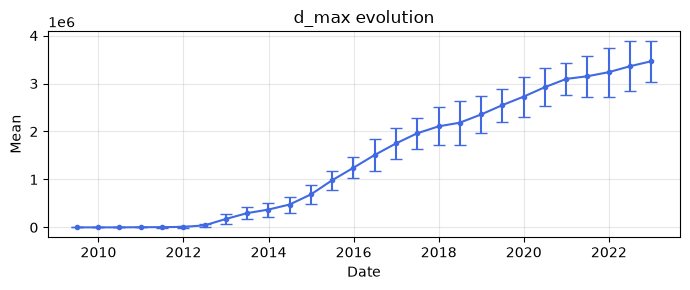

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.errorbar(result['date'], result['d_max_mean'], yerr=result["d_max_std"], color="royalblue", fmt=".-", capsize=4, label="d_max")
#ax.plot(result['date'], result['d_min_mean'], color="orange", marker='.')
ax.set_xlabel("Date")
ax.set_ylabel("Mean")
ax.set_title("d_max evolution")
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

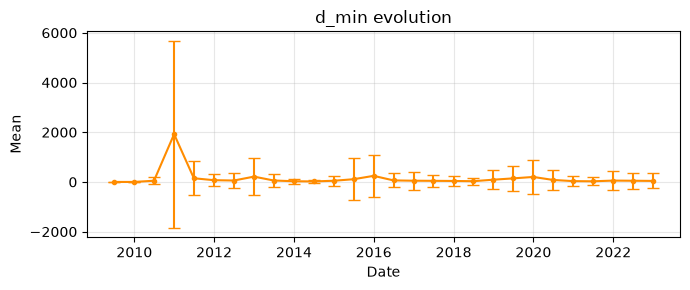

In [30]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.errorbar(result['date'], result['d_min_mean'], yerr=result["d_min_std"], color="darkorange", fmt=".-", capsize=4, label="d_min")
ax.set_xlabel("Date")
ax.set_ylabel("Mean")
ax.set_title("d_min evolution")
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

In [35]:
def hellinger_distance(df1, df2):
    n = max(df1.height, df2.height)
    p = np.zeros(n)
    q = np.zeros(n)
    p[:df1.height] = df1["count"].to_numpy()
    q[:df2.height] = df2["count"].to_numpy()
    p /= p.sum()
    q /= q.sum()
    return np.sqrt(np.sum((np.sqrt(p) - np.sqrt(q)) ** 2) / 2)

names = [f"dist_{year}_H{h}.bin" for year in range(2009, 2023) for h in [1, 2]]
dmax_dists = []
dmin_dists = []

# d_max

with open(f"results/dist_dmax/{names[0]}", "rb") as f:
    arr = np.fromfile(f, dtype=np.dtype([('d_max', '<u4'), ('count', '<u8')]))
    prev_df = pl.DataFrame({"d_max": arr["d_max"], "count":  arr["count"],})

for i in range(1, len(names)):
    with open(f"results/dist_dmax/{names[i]}", "rb") as f:
        arr = np.fromfile(f, dtype=np.dtype([('d_max', '<u4'), ('count', '<u8')]))
        curr_df = pl.DataFrame({"d_max": arr["d_max"], "count":  arr["count"],})
        hellinger_dist = hellinger_distance(prev_df, curr_df)
        dmax_dists.append(hellinger_dist)
        #print(f"Hellinger distance between {names[i-1]} and {names[i]}: {hellinger_dist:.4f}")
        prev_df = curr_df

# d_min

with open(f"results/dist_dmin/{names[0]}", "rb") as f:
    arr = np.fromfile(f, dtype=np.dtype([('d_min', '<u4'), ('count', '<u8')]))
    prev_df = pl.DataFrame({"d_min": arr["d_min"], "count":  arr["count"],})

for i in range(1, len(names)):
    with open(f"results/dist_dmin/{names[i]}", "rb") as f:
        arr = np.fromfile(f, dtype=np.dtype([('d_min', '<u4'), ('count', '<u8')]))
        curr_df = pl.DataFrame({"d_min": arr["d_min"], "count":  arr["count"],})
        hellinger_dist = hellinger_distance(prev_df, curr_df)
        dmin_dists.append(hellinger_dist)
        #print(f"Hellinger distance between {names[i-1]} and {names[i]}: {hellinger_dist:.4f}")
        prev_df = curr_df



In [36]:
dates = [datetime.date(year, 6, 30) if h == 1 else datetime.date(year, 12, 31) for year in range(2009, 2023) for h in [1, 2]]
result = pl.DataFrame({"date": dates[1:], "d_max_dist": dmax_dists, "d_min_dist": dmin_dists})
result

date,d_max_dist,d_min_dist
date,f64,f64
2009-12-31,0.015655,0.019246
2010-06-30,0.348961,0.347503
2010-12-31,0.556953,0.524661
2011-06-30,0.499106,0.474601
2011-12-31,0.349971,0.126589
…,…,…
2020-12-31,0.754621,0.102269
2021-06-30,0.885623,0.055579
2021-12-31,0.92182,0.07566


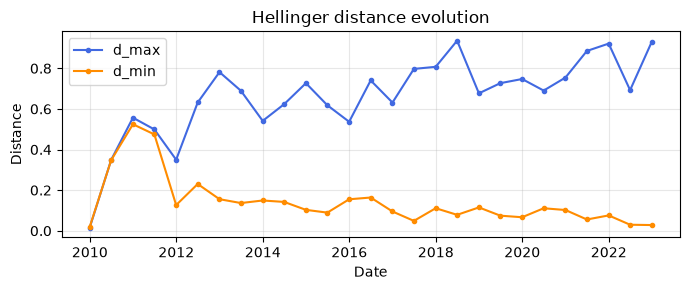

In [38]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(result['date'], result['d_max_dist'], color="royalblue", marker='.', label="d_max")
ax.plot(result['date'], result['d_min_dist'], color="darkorange", marker='.', label="d_min")
ax.set_xlabel("Date")
ax.set_ylabel("Distance")
ax.set_title("Hellinger distance evolution")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

In [15]:
def hellinger_distance(df1, df2):
    n = max(df1.height, df2.height)
    p = np.zeros(n)
    q = np.zeros(n)
    p[:df1.height] = df1["count"].to_numpy()
    q[:df2.height] = df2["count"].to_numpy()
    p /= p.sum()
    q /= q.sum()
    return np.sqrt(np.sum((np.sqrt(p) - np.sqrt(q)) ** 2) / 2)


names = [f"dist_{year}_H{h}.bin" for year in range(2009, 2023) for h in [1, 2]]
dates = [datetime.date(year, 6, 30) if h == 1 else datetime.date(year, 12, 31) for year in range(2009, 2023) for h in [1, 2]]

n = len(names)
hellinger_matrix = np.zeros((n, n))

for i in range(n):
    f_1 = open(f"results/dist_dmax/{names[i]}", "rb")
    arr_1 = np.fromfile(f_1, dtype=np.dtype([('d_max', '<u4'), ('count', '<u8')]))
    dist_1 = pl.DataFrame({"d_max": arr_1["d_max"], "count":  arr_1["count"],})
    f_1.close()
    for j in range(i+1, n):
        f_2 = open(f"results/dist_dmax/{names[j]}", "rb")
        arr_2 = np.fromfile(f_2, dtype=np.dtype([('d_max', '<u4'), ('count', '<u8')]))
        dist_2 = pl.DataFrame({"d_max": arr_2["d_max"], "count":  arr_2["count"],})
        f_2.close()
        hellinger_matrix[i, j] = hellinger_distance(dist_1, dist_2)
        hellinger_matrix[j, i] = hellinger_distance(dist_1, dist_2)

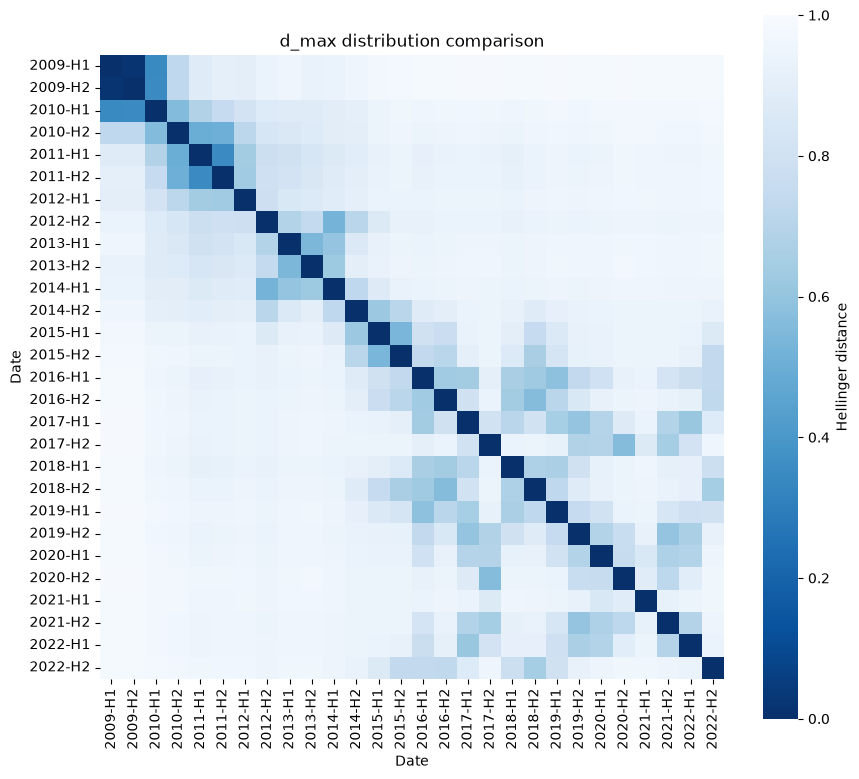

In [16]:
labels = [f"{year}-H{h}" for year in range(2009, 2023) for h in [1, 2]]

plt.figure(figsize=(9, 8))
plt.title("d_max distribution comparison")

sns.heatmap(
    hellinger_matrix,
    xticklabels=labels,
    yticklabels=labels,
    cmap="Blues_r",
    vmin=0,
    vmax=1,
    square=True,
    cbar_kws={"label": "Hellinger distance"},
)

plt.xticks(rotation=90, ha="center")
plt.yticks(rotation=0)
plt.xlabel("Date")
plt.ylabel("Date")
plt.tight_layout()
plt.show()

In [17]:
def hellinger_distance(df1, df2):
    n = max(df1.height, df2.height)
    p = np.zeros(n)
    q = np.zeros(n)
    p[:df1.height] = df1["count"].to_numpy()
    q[:df2.height] = df2["count"].to_numpy()
    p /= p.sum()
    q /= q.sum()
    return np.sqrt(np.sum((np.sqrt(p) - np.sqrt(q)) ** 2) / 2)


names = [f"dist_{year}_H{h}.bin" for year in range(2009, 2023) for h in [1, 2]]
dates = [datetime.date(year, 6, 30) if h == 1 else datetime.date(year, 12, 31) for year in range(2009, 2023) for h in [1, 2]]

n = len(names)
hellinger_matrix = np.zeros((n, n))

for i in range(n):
    f_1 = open(f"results/dist_dmin/{names[i]}", "rb")
    arr_1 = np.fromfile(f_1, dtype=np.dtype([('d_min', '<u4'), ('count', '<u8')]))
    dist_1 = pl.DataFrame({"d_min": arr_1["d_min"], "count":  arr_1["count"],})
    f_1.close()
    for j in range(i+1, n):
        f_2 = open(f"results/dist_dmin/{names[j]}", "rb")
        arr_2 = np.fromfile(f_2, dtype=np.dtype([('d_min', '<u4'), ('count', '<u8')]))
        dist_2 = pl.DataFrame({"d_min": arr_2["d_min"], "count":  arr_2["count"],})
        f_2.close()
        hellinger_matrix[i, j] = hellinger_distance(dist_1, dist_2)
        hellinger_matrix[j, i] = hellinger_distance(dist_1, dist_2)

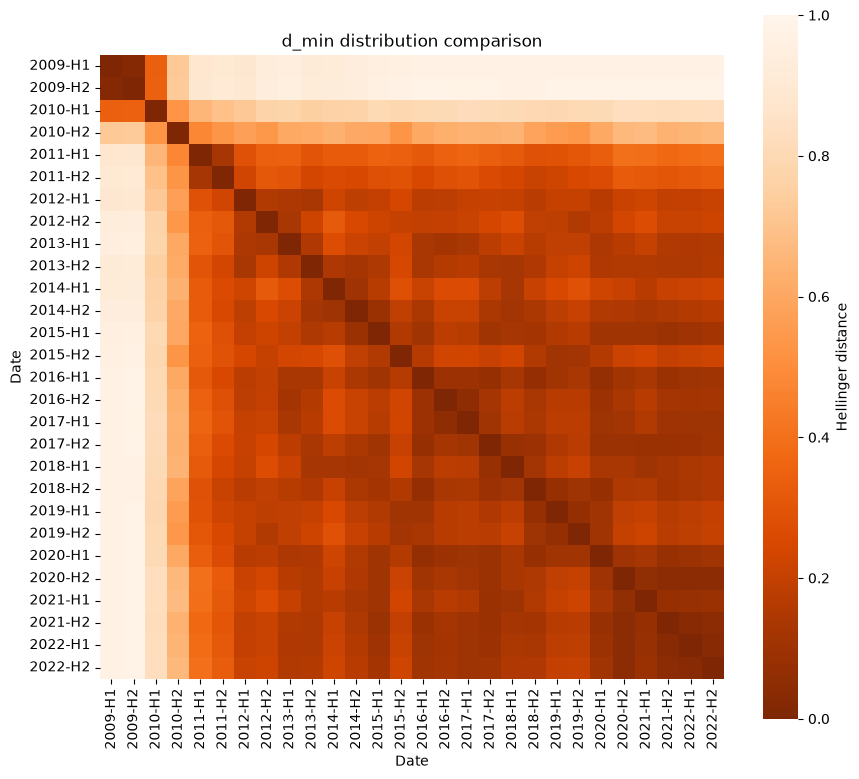

In [18]:
labels = [f"{year}-H{h}" for year in range(2009, 2023) for h in [1, 2]]

plt.figure(figsize=(9, 8))
plt.title("d_min distribution comparison")

sns.heatmap(
    hellinger_matrix,
    xticklabels=labels,
    yticklabels=labels,
    cmap="Oranges_r",
    vmin=0,
    vmax=1,
    square=True,
    cbar_kws={"label": "Hellinger distance"},
)

plt.xticks(rotation=90, ha="center")
plt.yticks(rotation=0)
plt.xlabel("Date")
plt.ylabel("Date")
plt.tight_layout()
plt.show()